<a href="https://colab.research.google.com/github/martinn308/AI-FOR-SCIENCE-AND-ENGINEERING-JKUAT/blob/Week-2/Week4_Math_of_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 Assignment: Exploring the Mathematics of My Data

**Project:** Predicting housing prices/demand
**Dataset:** Same housing dataset imported in the earlier

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/Shivang1179793/House-Price-Prediction/main/housing.csv"
df = pd.read_csv(url)
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


## 1. Selected Variables
I picked four numerical variables relevant to my project:
- Avg. Area Income
- Avg. Area House Age
- Area Population`
- Price

In [7]:
variables = ["Avg. Area Income", "Avg. Area House Age", "Area Population", "Price"]

rows = []
for v in variables:
    s = df[v]
    rows.append({
        "Variable": v,
        "Mean": s.mean(),
        "Median": s.median(),
        "Range": s.max() - s.min(),
        "Variance": s.var(),
        "Std Dev": s.std(),
    })

stats = pd.DataFrame(rows).set_index("Variable")
pd.options.display.float_format = "{:,.2f}".format
stats

,Mean,Median,Range,Variance,Std Dev
Variable,,,,,
Avg. Area Income,"68,583.11","68,804.29","89,905.12","113,592,776.71","10,657.99"
Avg. Area House Age,5.98,5.97,6.87,0.98,0.99
Area Population,"36,163.52","36,199.41","69,449.10","98,518,530.18","9,925.65"
Price,"1,232,072.65","1,232,669.38","2,453,126.94","124,692,058,202.24","353,117.63"


## 2. Covariance and Correlation
I chose Avg. Area Income and Price

In [8]:
x = df["Avg. Area Income"]
y = df["Price"]

covariance = np.cov(x, y)[0, 1]
correlation = np.corrcoef(x, y)[0, 1]

print(f"Covariance (Income, Price): {covariance:,.2f}")
print(f"Correlation (Income, Price): {correlation:.4f}")

Covariance (Income, Price): 2,407,653,787.30
Correlation (Income, Price): 0.6397


## 3. Plot: Income vs Price

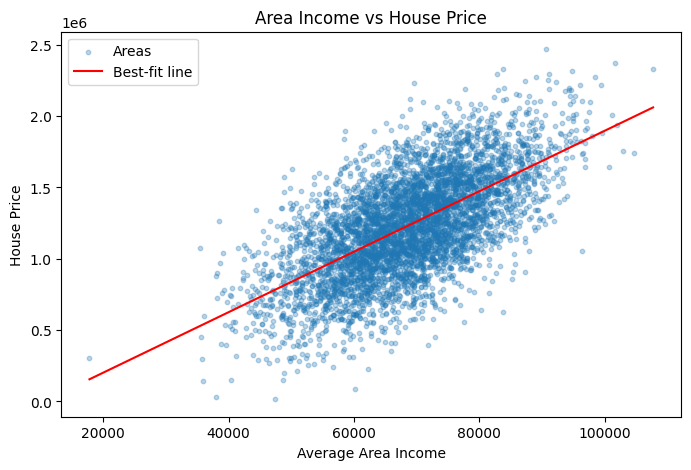

In [9]:
slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.3, s=10, label="Areas")
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, intercept + slope * xs, color="red", label="Best-fit line")
plt.xlabel("Average Area Income")
plt.ylabel("House Price")
plt.title("Area Income vs House Price")
plt.legend()
plt.show()


## 4. What the Results Tell Me

- **Statistics:** Mean and median are close, suggesting the data may not be heavily skewed. Price has a large spread, and the range shows the difference between the lowest and highest prices.

- **Correlation:** Income and price have a positive correlation of **0.64**, meaning areas with higher incomes tend to have higher house prices.

- **Correlation vs. Causation:** Correlation does not prove causation. Income and house prices may both be influenced by factors such as location and access to services.

## 5. Input → Function/Model → Output

**Input (x):** Average Area Income
**Output (y):** House Price

$$\text{Input } (x) \;\rightarrow\; f(x) \;\rightarrow\; \text{Output } (y)$$

A simple model is a straight line:

$$y = f(x) = \beta_0 + \beta_1 x$$

where $\beta_0$ is the starting value (intercept) and $\beta_1$ is how much price changes for each 1 unit increase in income. The code below finds these values from the data.

In [11]:
def f(income):
    return intercept + slope * income

print(f"Price = {intercept:,.2f} + {slope:.4f} Income")
print(f"Example:The income of 70,000 -> predicted price of {f(70000):,.2f}")

Price = -221,579.48 + 21.1955 Income
Example:The income of 70,000 -> predicted price of 1,262,104.34
